**IMPORT LIBRARY**

In [ ]:
!pip install tensorflow keras numpy pandas matplotlib seaborn scikit-learn ipython imagehash pillow rembg onnxruntime opencv-python

In [ ]:
import os
import cv2
import tensorflow as tf
import numpy as np
import pandas as pd
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.layers import Dense, Activation,Dropout,Conv2D, MaxPooling2D,BatchNormalization,Input, GlobalAveragePooling2D, GlobalMaxPooling2D, Layer
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model, load_model, Sequential
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from keras.callbacks import ModelCheckpoint
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.pyplot import imshow
import seaborn as sns
sns.set_style('darkgrid')
from sklearn.metrics import confusion_matrix, classification_report
from IPython.display import display, HTML
import random
from PIL import Image, ImageEnhance
import time
from tqdm import tqdm
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
import shutil
from pathlib import Path
from rembg import remove, new_session

**LOAD DATA**

In [ ]:
# import numpy as np
# import pandas as pd
# import os
# import seaborn as sns
# sns.set_style('darkgrid')
# from PIL import Image, ImageEnhance
# import seaborn as sns
# import matplotlib.pyplot as plt
# import random

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
input_dir=r'/content/drive/MyDrive/SKRIPSI/DATASET_REAL'

In [ ]:
classes = [d for d in os.listdir(input_dir) if os.path.isdir(os.path.join(input_dir, d))]
print("Classes:", classes)

Classes: ['Lumpy Skin', 'Normal Skin']


Lumpy Skin: 324 gambar
Normal Skin: 700 gambar
Total semua gambar: 1024


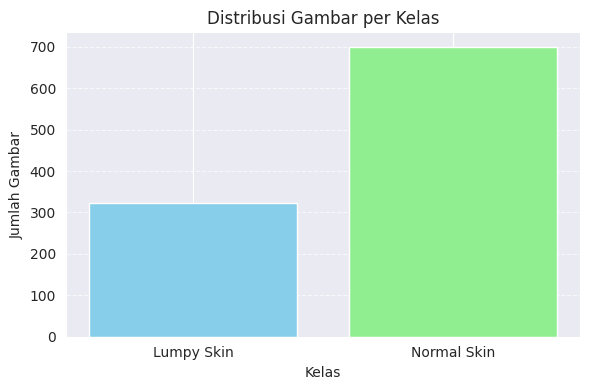

In [ ]:
total_images = 0
class_counts = {}
for class_name in classes:
    class_path = os.path.join(input_dir, class_name)
    if os.path.isdir(class_path):
        image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('jpg', 'jpeg', 'png'))]
        count = len(image_files)
        class_counts[class_name] = count
        total_images += count

for cls, count in class_counts.items():
    print(f"{cls}: {count} gambar")
print("Total semua gambar:", total_images)

plt.figure(figsize=(6, 4))
plt.bar(class_counts.keys(), class_counts.values(), color=['skyblue', 'lightgreen'])
plt.title("Distribusi Gambar per Kelas")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Gambar")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
input_dir=r'/content/drive/MyDrive/SKRIPSI/Dataset'

Distribusi data:
Lumpy Skin: 310 gambar
Normal Skin: 562 gambar
Total semua gambar: 872


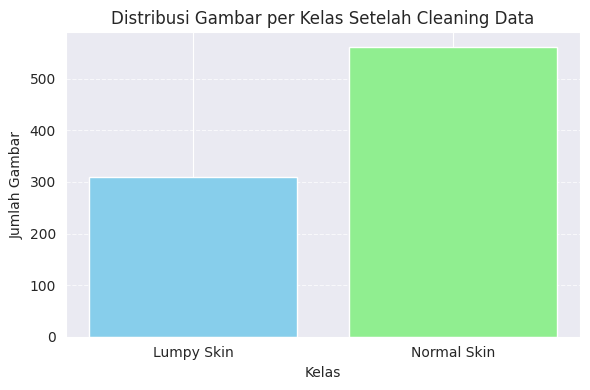

In [ ]:
total_images = 0
class_counts = {}
for class_name in classes:
    class_path = os.path.join(input_dir, class_name)
    if os.path.isdir(class_path):
        image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('jpg', 'jpeg', 'png'))]
        count = len(image_files)
        class_counts[class_name] = count
        total_images += count

print("Distribusi data:")
for cls, count in class_counts.items():
    print(f"{cls}: {count} gambar")
print("Total semua gambar:", total_images)

# Visualisasi bar chart
plt.figure(figsize=(6, 4))
plt.bar(class_counts.keys(), class_counts.values(), color=['skyblue', 'lightgreen'])
plt.title("Distribusi Gambar per Kelas Setelah Cleaning Data")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Gambar")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
all_images = []
for class_name in classes:
    class_path = os.path.join(input_dir, class_name)
    img_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    for img_name in img_files:
        img_path = os.path.join(class_path, img_name)
        all_images.append((img_path, class_name))

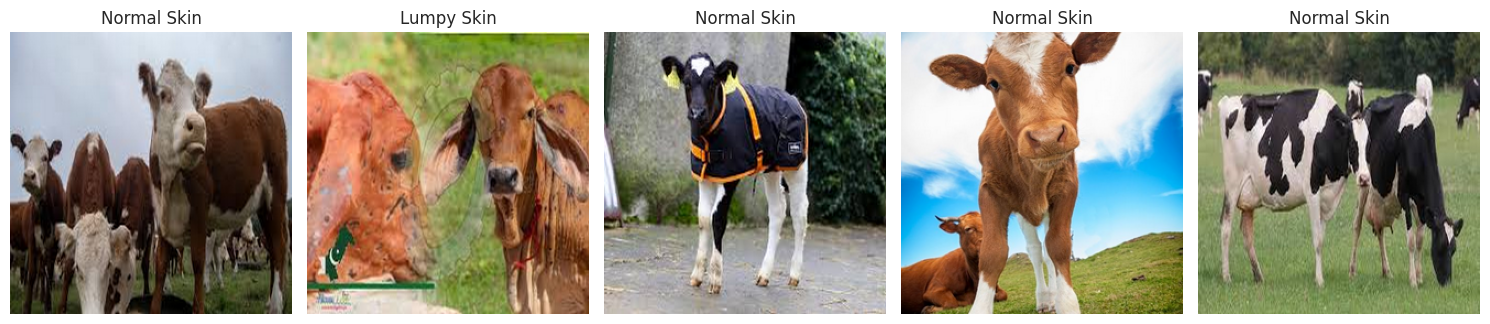

In [ ]:
random.shuffle(all_images)
sample_images = all_images[:5]

# Tampilkan
plt.figure(figsize=(15, 5))
for i, (img_path, label) in enumerate(sample_images):
    try:
        img = Image.open(img_path).convert("RGB")
        plt.subplot(1, 5, i+1)
        plt.imshow(img)
        plt.title(label)
        plt.axis('off')

    except Exception as e:
        print(f"Gagal membuka {img_path}: {e}")
plt.tight_layout()
plt.show()

NILAI PIXEL

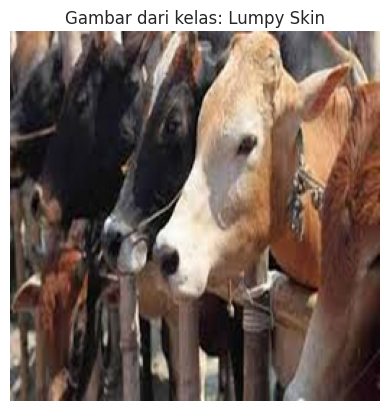

In [ ]:
# Ambil satu gambar dari kelas pertama
sample_class = classes[0]
sample_path = os.path.join(input_dir, sample_class)
sample_img_name = random.choice(os.listdir(sample_path))
sample_img_path = os.path.join(sample_path, sample_img_name)

# Baca gambar
img = cv2.imread(sample_img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Tampilkan gambar
plt.imshow(img_rgb)
plt.title(f"Gambar dari kelas: {sample_class}")
plt.axis("off")
plt.show()

In [ ]:
R = img_rgb[:, :, 0]
G = img_rgb[:, :, 1]
B = img_rgb[:, :, 2]

print("Channel R (Red):")
print(R[:5, :5])

print("\nChannel G (Green):")
print(G[:5, :5])

print("\nChannel B (Blue):")
print(B[:5, :5])

Channel R (Red):
[[198 227 246 214 138]
 [203 230 247 223 151]
 [210 234 251 239 173]
 [206 234 254 246 183]
 [194 231 255 249 185]]

Channel G (Green):
[[188 216 233 199 119]
 [193 218 233 207 133]
 [199 222 236 221 154]
 [194 221 240 228 162]
 [181 218 242 230 163]]

Channel B (Blue):
[[176 204 218 184 104]
 [181 205 219 192 116]
 [187 208 223 206 137]
 [180 208 226 213 146]
 [167 203 227 215 146]]


In [ ]:
classes = sorted(os.listdir(input_dir))
label_map = {i: name for i, name in enumerate(classes)}
print("Label encoding:", label_map)

Label encoding: {0: 'Lumpy Skin', 1: 'Normal Skin'}


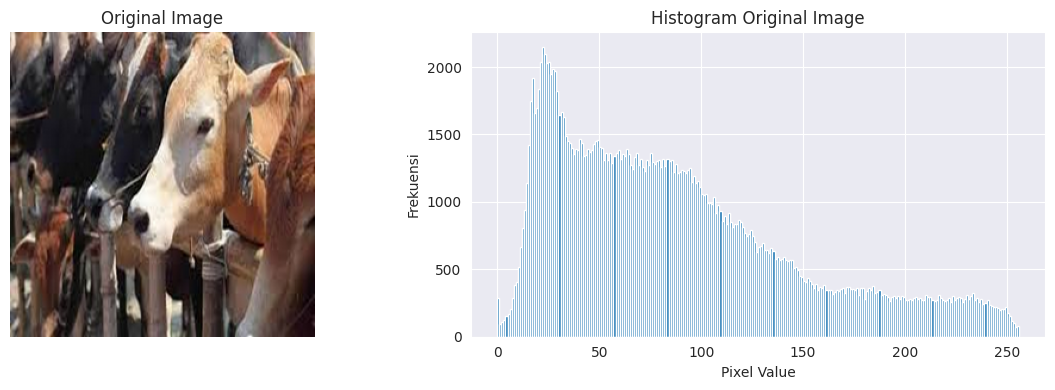

In [ ]:
classes = os.listdir(input_dir)
original_img = cv2.imread(sample_img_path)

plt.figure(figsize=(12,4))

# Gambar Asli
plt.subplot(1,2,1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.axis("off")

# Histogram
plt.subplot(1,2,2)
plt.title("Histogram Original Image")
plt.hist(original_img.ravel(), bins=256, range=(0,256))
plt.xlabel("Pixel Value")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()


In [ ]:
print("Nilai pixel Original Image (5x5):")
print(original_img[:5, :5])

Nilai pixel Original Image (5x5):
[[[176 188 198]
  [204 216 227]
  [218 233 246]
  [184 199 214]
  [104 119 138]]

 [[181 193 203]
  [205 218 230]
  [219 233 247]
  [192 207 223]
  [116 133 151]]

 [[187 199 210]
  [208 222 234]
  [223 236 251]
  [206 221 239]
  [137 154 173]]

 [[180 194 206]
  [208 221 234]
  [226 240 254]
  [213 228 246]
  [146 162 183]]

 [[167 181 194]
  [203 218 231]
  [227 242 255]
  [215 230 249]
  [146 163 185]]]


Segmentasi U2NET

In [ ]:
output_dir = r'/content/drive/MyDrive/SKRIPSI/Dataset_NoBG'

In [ ]:
# !pip install rembg[gpu] pillow tqdm matplotlib

# ── 2. Import libraries ──────────────────────────────────────
# import os
# from pathlib import Path
# from PIL import Image
# from rembg import remove, new_session
# from tqdm import tqdm

# # ── 3. Konfigurasi Path ──────────────────────────────────────
# input_dir  = r'/content/drive/MyDrive/SKRIPSI/Dataset'
output_dir = r'/content/drive/MyDrive/SKRIPSI/Dataset_NoBG'

# Format gambar yang didukung
SUPPORTED_FORMATS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tiff'}

# ── 4.  Model rembg ─────────────────────────────────────
MODEL_NAME = 'u2net'

# ── 5. Fungsi Remove Background ──────────────────────────────
def remove_background_dataset(
    input_dir: str,
    output_dir: str,
    model_name: str = 'u2net',
    keep_subfolder_structure: bool = True
):
    """
    Menghapus background dari semua gambar di input_dir
    dan menyimpan hasilnya ke output_dir.

    Args:
        input_dir  : Direktori sumber dataset
        output_dir : Direktori output hasil remove BG
        model_name : Model rembg yang digunakan
        keep_subfolder_structure : Pertahankan struktur subfolder
    """
    input_path  = Path(input_dir)
    output_path = Path(output_dir)

    if not input_path.exists():
        raise FileNotFoundError(f"Input directory tidak ditemukan: {input_dir}")

    output_path.mkdir(parents=True, exist_ok=True)

    # Kumpulkan semua file gambar (rekursif)
    all_images = [
        f for f in input_path.rglob('*')
        if f.suffix.lower() in SUPPORTED_FORMATS
    ]

    if not all_images:
        print("⚠️  Tidak ada gambar ditemukan di direktori input.")
        return

    print(f"📁 Input  : {input_dir}")
    print(f"📁 Output : {output_dir}")
    print(f"🤖 Model  : {model_name}")
    print(f"🖼️  Total  : {len(all_images)} gambar\n")

    # Inisialisasi session model (lebih efisien daripada reload tiap gambar)
    session = new_session(model_name)

    success_count = 0
    error_count   = 0
    skipped_count = 0

    for img_path in tqdm(all_images, desc="Processing", unit="img"):
        try:
            # Tentukan path output
            if keep_subfolder_structure:
                relative = img_path.relative_to(input_path)
                out_file = output_path / relative.parent / (img_path.stem + '.png')
            else:
                out_file = output_path / (img_path.stem + '.png')

            # Skip jika sudah diproses
            if out_file.exists():
                skipped_count += 1
                continue

            out_file.parent.mkdir(parents=True, exist_ok=True)

            # Buka gambar
            with Image.open(img_path) as img:
                # Konversi ke RGBA jika perlu
                img = img.convert('RGBA')

                # Remove background
                result = remove(img, session=session)

                # Simpan sebagai PNG (mempertahankan transparansi)
                result.save(out_file, format='PNG')

            success_count += 1

        except Exception as e:
            error_count += 1
            tqdm.write(f"❌ Error pada {img_path.name}: {e}")

    # ── Laporan Hasil ─────────────────────────────────────────
    print("\n" + "="*50)
    print("✅ SELESAI!")
    print(f"   Berhasil  : {success_count} gambar")
    print(f"   Dilewati  : {skipped_count} gambar (sudah ada)")
    print(f"   Gagal     : {error_count} gambar")
    print(f"   Output    : {output_dir}")
    print("="*50)

# ── 6. Jalankan ──────────────────────────────────────────────
if __name__ == '__main__':
    remove_background_dataset(
        input_dir  = input_dir,
        output_dir = output_dir,
        model_name = MODEL_NAME,
        keep_subfolder_structure = True   # False = semua flat di output_dir
    )

def _make_checkerboard(size, tile=20):
    """Buat background checkerboard untuk visualisasi transparansi."""
    w, h   = size
    checker = Image.new('RGB', (w, h))
    for y in range(0, h, tile):
        for x in range(0, w, tile):
            color = (200, 200, 200) if (x // tile + y // tile) % 2 == 0 else (255, 255, 255)
            for py in range(min(tile, h - y)):
                for px in range(min(tile, w - x)):
                    checker.putpixel((x + px, y + py), color)
    return checker


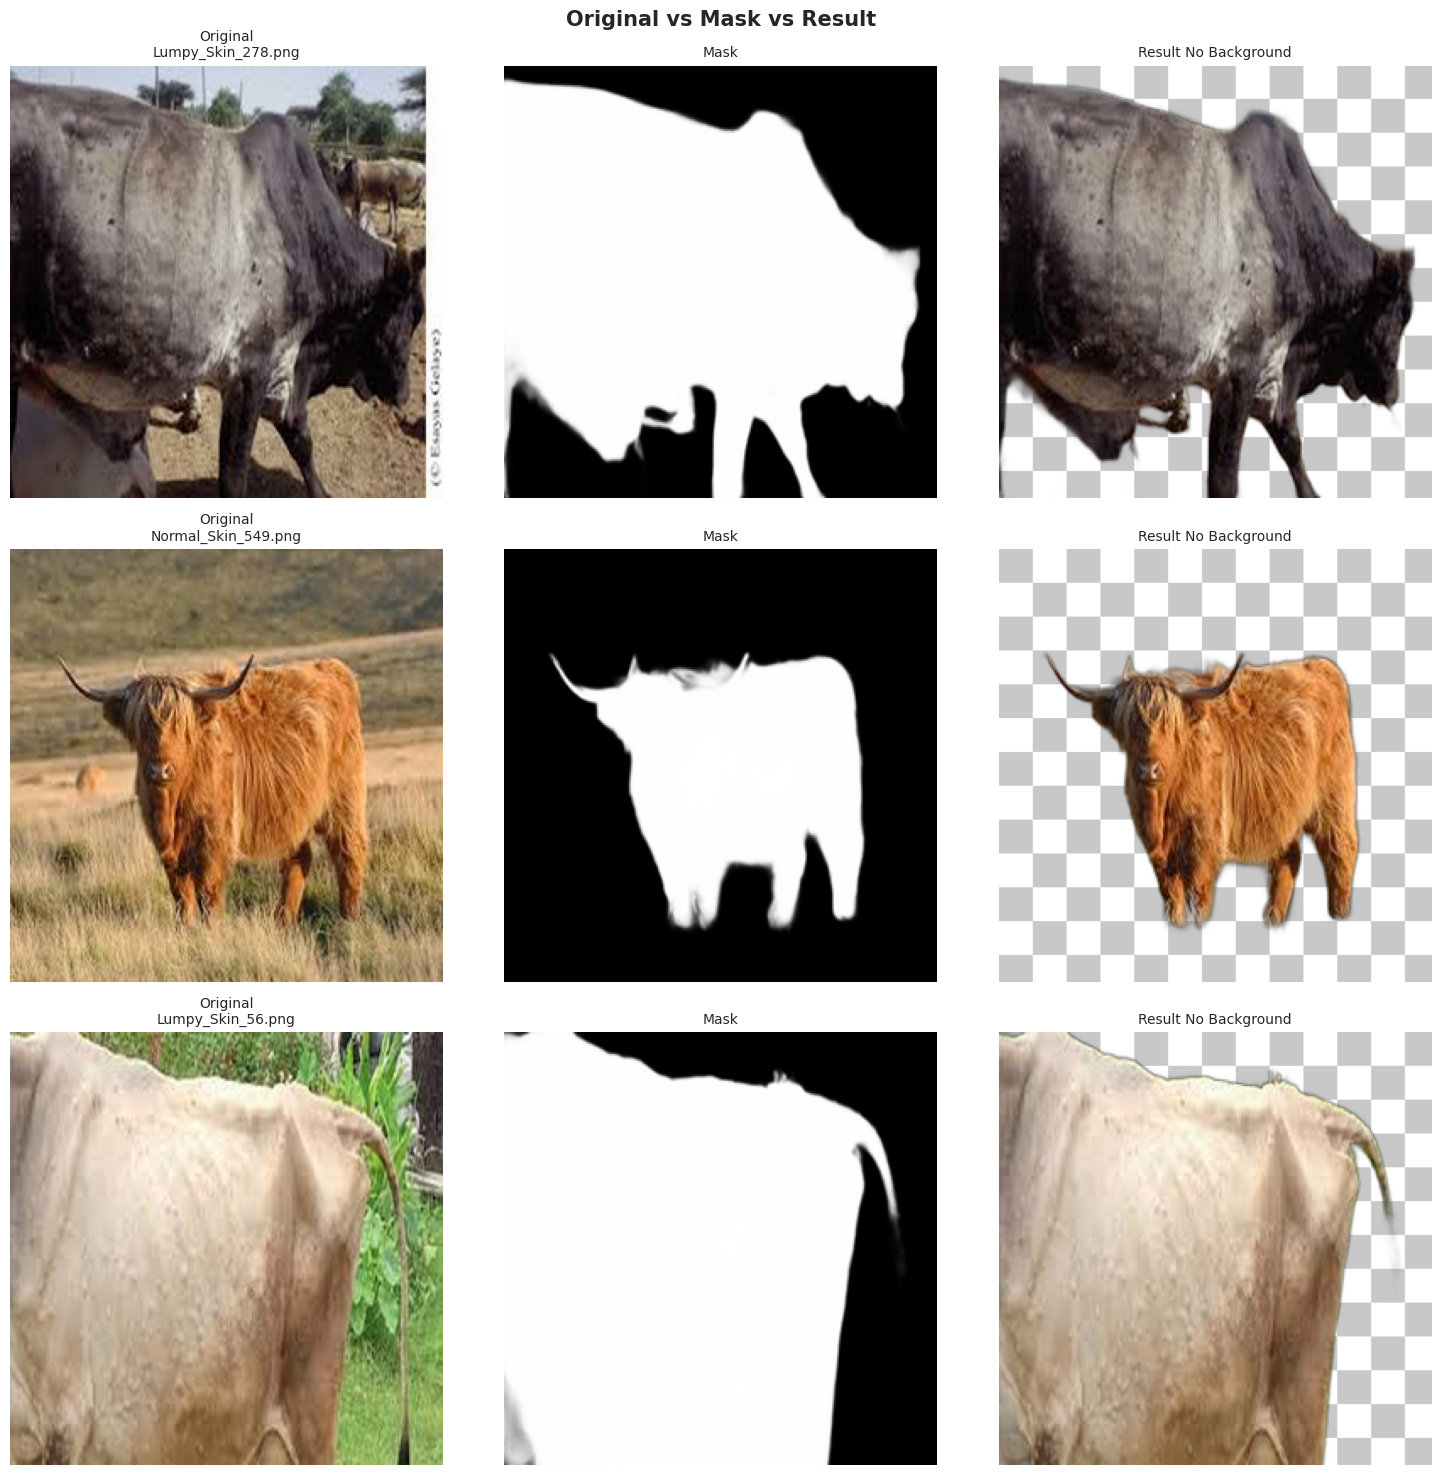

In [ ]:
# ── Preview Original, Mask, dan Result ───────────────────────
def preview_ori_mask_result(input_dir: str, output_dir: str, n_samples: int = 3):
    """
    Menampilkan:
    1. Original Image
    2. Mask hasil segmentasi
    3. Result remove background
    """

    import matplotlib.pyplot as plt
    import random
    import numpy as np

    input_path  = Path(input_dir)
    output_path = Path(output_dir)

    out_images = list(output_path.rglob('*.png'))

    if len(out_images) == 0:
        print("Tidak ada hasil PNG ditemukan.")
        return

    samples = random.sample(out_images, min(n_samples, len(out_images)))

    fig, axes = plt.subplots(len(samples), 3, figsize=(15, 5 * len(samples)))

    if len(samples) == 1:
        axes = [axes]

    for ax_row, out_img_path in zip(axes, samples):

        relative  = out_img_path.relative_to(output_path)
        orig_stem = relative.parent / relative.stem

        # Cari file original
        orig_file = None
        for ext in SUPPORTED_FORMATS:
            candidate = input_path / orig_stem.parent / (orig_stem.name + ext)
            if candidate.exists():
                orig_file = candidate
                break

        # ── ORIGINAL ─────────────────────────────
        if orig_file:
            original_img = Image.open(orig_file).convert("RGB")
            ax_row[0].imshow(original_img)
            ax_row[0].set_title(f"Original\n{orig_file.name}", fontsize=10)
        else:
            ax_row[0].set_title("Original tidak ditemukan")

        ax_row[0].axis('off')

        # ── RESULT (RGBA) ───────────────────────
        result_img = Image.open(out_img_path).convert("RGBA")

        # ── MASK ────────────────────────────────
        # Ambil alpha channel sebagai mask
        mask = np.array(result_img.split()[-1])

        ax_row[1].imshow(mask, cmap='gray')
        ax_row[1].set_title("Mask", fontsize=10)
        ax_row[1].axis('off')

        # ── RESULT FINAL ────────────────────────
        checker = _make_checkerboard(result_img.size)
        checker.paste(result_img, mask=result_img.split()[3])

        ax_row[2].imshow(checker)
        ax_row[2].set_title("Result No Background", fontsize=10)
        ax_row[2].axis('off')

    plt.suptitle("Original vs Mask vs Result", fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

preview_ori_mask_result(
    input_dir=input_dir,
    output_dir=output_dir,
    n_samples=3
)

RESIZE

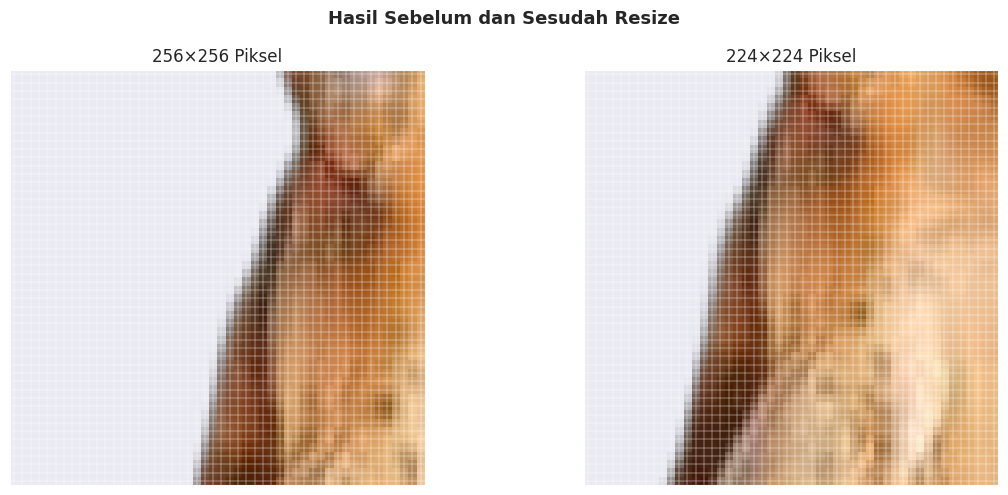

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

# Ambil kelas secara acak
sample_class = random.choice(classes)

# Cari gambar hasil segmentasi
seg_folder = os.path.join(output_dir, sample_class)

sample_img = random.choice(
    [f for f in os.listdir(seg_folder)
     if f.lower().endswith('.png')]
)

seg_path = os.path.join(seg_folder, sample_img)

# Baca gambar segmentasi (ukuran asli 256x256)
img_seg = cv2.imread(seg_path, cv2.IMREAD_UNCHANGED)

if img_seg.shape[-1] == 4:
    img_seg = cv2.cvtColor(img_seg, cv2.COLOR_BGRA2RGBA)
else:
    img_seg = cv2.cvtColor(img_seg, cv2.COLOR_BGR2RGB)

# Resize menjadi 224x224
img_resize = cv2.resize(img_seg, (224, 224))

# Crop area kecil agar struktur piksel terlihat
crop_seg = img_seg[50:100, 50:100]
crop_resize = img_resize[50:100, 50:100]

# Visualisasi
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Sebelum resize
ax[0].imshow(crop_seg, interpolation='nearest')
ax[0].set_title('256×256 Piksel')
ax[0].set_xticks(range(crop_seg.shape[1]))
ax[0].set_yticks(range(crop_seg.shape[0]))
ax[0].grid(color='white', linewidth=0.3)
ax[0].tick_params(labelbottom=False, labelleft=False)

# Setelah resize
ax[1].imshow(crop_resize, interpolation='nearest')
ax[1].set_title('224×224 Piksel')
ax[1].set_xticks(range(crop_resize.shape[1]))
ax[1].set_yticks(range(crop_resize.shape[0]))
ax[1].grid(color='white', linewidth=0.3)
ax[1].tick_params(labelbottom=False, labelleft=False)

plt.suptitle(
    'Hasil Sebelum dan Sesudah Resize',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

SPLITTING DATA

In [ ]:
all_data = []
for class_name in classes:
    class_path = os.path.join(output_dir, class_name)
    for fname in os.listdir(class_path):
        all_data.append((os.path.join(class_path, fname), class_name))

# 80% train, 20% sementara
train, val_test = train_test_split(all_data, test_size=0.2, stratify=[label for _, label in all_data], random_state=42)
# 10% validation, 10% test
val, test = train_test_split(val_test, test_size=0.5, stratify=[label for _, label in val_test], random_state=42)

In [ ]:
from collections import Counter

def count_classes(data):
    return dict(Counter([label for _, label in data]))

# Hitung jumlah per kelas
print("Total data:", len(all_data))
print("Train set:", len(train), "| Kelas:", count_classes(train))
print("Validation set:", len(val), "| Kelas:", count_classes(val))
print("Test set:", len(test), "| Kelas:", count_classes(test))

Total data: 872
Train set: 697 | Kelas: {'Normal Skin': 449, 'Lumpy Skin': 248}
Validation set: 87 | Kelas: {'Normal Skin': 56, 'Lumpy Skin': 31}
Test set: 88 | Kelas: {'Lumpy Skin': 31, 'Normal Skin': 57}


In [ ]:
# Save split
import pickle

with open("train_split.pkl", "wb") as f:
    pickle.dump(train, f)
with open("val_split.pkl", "wb") as f:
    pickle.dump(val, f)
with open("test_split.pkl", "wb") as f:
    pickle.dump(test, f)

In [ ]:
# Base direktori untuk menyimpan dataset yang sudah dipisah
final_dir = "/content/drive/MyDrive/SKRIPSI/Skenario 1&2/Data_Split"
splits = {'train': train, 'val': val, 'test': test}

In [ ]:
import shutil
# Buat folder dan salin gambar
for split_name, split_data in splits.items():
    for img_path, label in split_data:
        dest_dir = os.path.join(final_dir, split_name, label)
        os.makedirs(dest_dir, exist_ok=True)
        dest_path = os.path.join(dest_dir, os.path.basename(img_path))
        shutil.copy(img_path, dest_path)

print("Pemindahan file ke final_dataset selesai.")

Pemindahan file ke final_dataset selesai.


**AUGMENTASI**

In [ ]:
original_train = '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/Data_Split/train'
augmented_dir = '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/augmentasi/augmented_only'

In [ ]:
def apply_augmentation(cv_img):
    # Rotasi kecil ±10 derajat
    if random.random() < 0.3:
        angle = random.uniform(-10, 10)
        h, w = cv_img.shape[:2]
        M = cv2.getRotationMatrix2D((w//2, h//2), angle, 1)
        cv_img = cv2.warpAffine(cv_img, M, (w, h), borderMode=cv2.BORDER_REFLECT)

    # Brightness adjustment (0.9 - 1.1)
    if random.random() < 0.2:
        factor = random.uniform(0.9, 1.1)
        pil_img = Image.fromarray(cv2.cvtColor(cv_img, cv2.COLOR_BGR2RGB))
        enhancer = ImageEnhance.Brightness(pil_img)
        pil_img = enhancer.enhance(factor)
        cv_img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    # Zoom in (1.0 - 1.2)
    if random.random() < 0.3:
        zoom_factor = random.uniform(1.0, 1.2)
        h, w = cv_img.shape[:2]
        new_h, new_w = int(h / zoom_factor), int(w / zoom_factor)
        top = random.randint(0, h - new_h)
        left = random.randint(0, w - new_w)
        cropped_img = cv_img[top:top+new_h, left:left+new_w]
        cv_img = cv2.resize(cropped_img, (w, h), interpolation=cv2.INTER_LINEAR)

    return cv_img

In [ ]:
print(os.path.exists(original_train))
print(os.listdir(original_train))

True
['Normal Skin', 'Lumpy Skin']


In [ ]:
os.makedirs(augmented_dir, exist_ok=True)

aug_count = 0

for class_name in os.listdir(original_train):
    class_path = os.path.join(original_train, class_name)
    class_aug_path = os.path.join(augmented_dir, class_name)
    os.makedirs(class_aug_path, exist_ok=True)

    for fname in os.listdir(class_path):
        img_path = os.path.join(class_path, fname)
        img = cv2.imread(img_path)

        for i in range(2):  #augmentasi 2x
            aug_img = apply_augmentation(img.copy())
            save_name = f"{os.path.splitext(fname)[0]}_aug{i}.jpg"
            save_path = os.path.join(class_aug_path, save_name)
            cv2.imwrite(save_path, aug_img)
            aug_count += 1

print(f" Augmentasi selesai: {aug_count} gambar disimpan ke {augmented_dir}")

 Augmentasi selesai: 1394 gambar disimpan ke /content/drive/MyDrive/SKRIPSI/Skenario 1&2/augmentasi/augmented_only


In [ ]:
cek_aug = augmented_dir

In [ ]:
classes_cek = [d for d in os.listdir(cek_aug) if os.path.isdir(os.path.join(cek_aug, d))]

In [ ]:
total_images = 0
class_counts = {}
for class_name in classes_cek:
    class_path = os.path.join(cek_aug, class_name)
    if os.path.isdir(class_path):
        image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('jpg', 'jpeg', 'png'))]
        count = len(image_files)
        class_counts[class_name] = count
        total_images += count

# Cetak hasil
print("Jumlah gambar per kelas:")
for class_name, count in class_counts.items():
    print(f"- {class_name}: {count} gambar")

print("\nTotal semua gambar:", total_images)

Jumlah gambar per kelas:
- Normal Skin: 898 gambar
- Lumpy Skin: 496 gambar

Total semua gambar: 1394


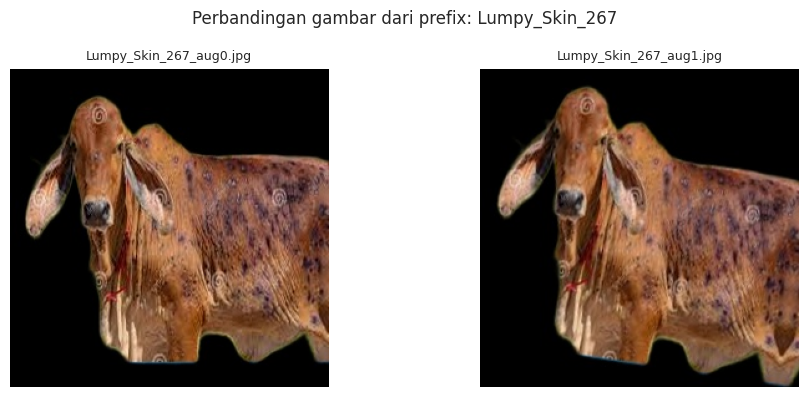

In [ ]:
import re

image_files = sorted([f for f in os.listdir(class_path) if f.lower().endswith(('jpg', 'jpeg', 'png'))])

# Buat dictionary untuk kelompokkan gambar berdasarkan prefix
grouped = {}
for filename in image_files:
    # Ambil prefix sebelum _aug (misalnya: gambar12_aug00.jpg → gambar12)
    match = re.match(r"(.*)_aug\d+", filename)
    if match:
        prefix = match.group(1)
        grouped.setdefault(prefix, []).append(filename)

# Ambil hanya yang punya minimal 2 augmentasi
paired_prefixes = [k for k, v in grouped.items() if len(v) >= 2]

if not paired_prefixes:
    print("Tidak ditemukan pasangan gambar berurutan.")
else:
    # Pilih 1 pasangan secara acak
    selected_prefix = random.choice(paired_prefixes)
    pair_files = sorted(grouped[selected_prefix])[:2]  # ambil 2 pertama

    img1_path = os.path.join(class_path, pair_files[0])
    img2_path = os.path.join(class_path, pair_files[1])

    img1 = cv2.imread(img1_path)
    img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

    img2 = cv2.imread(img2_path)
    img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

    # Tampilkan berdampingan
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img1)
    plt.title(pair_files[0], fontsize=9)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img2)
    plt.title(pair_files[1], fontsize=9)
    plt.axis('off')

    plt.suptitle(f"Perbandingan gambar dari prefix: {selected_prefix}", fontsize=12)
    plt.tight_layout()
    plt.show()

MENGGABUNGKAN AUGMENTARI DAN ORI

In [ ]:
combined_dir = '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/augmentasi/train'
os.makedirs(combined_dir, exist_ok=True)

In [ ]:
# Salin gambar asli
for class_name in os.listdir(original_train):
    src_class = os.path.join(original_train, class_name)
    dst_class = os.path.join(combined_dir, class_name)
    os.makedirs(dst_class, exist_ok=True)

    for fname in os.listdir(src_class):
        shutil.copy(os.path.join(src_class, fname), os.path.join(dst_class, fname))

In [ ]:
# Salin gambar augmentasi
for class_name in os.listdir(augmented_dir):
    src_class = os.path.join(augmented_dir, class_name)
    dst_class = os.path.join(combined_dir, class_name)
    os.makedirs(dst_class, exist_ok=True)

    for fname in os.listdir(src_class):
        shutil.copy(os.path.join(src_class, fname), os.path.join(dst_class, fname))

print(f" Gambar asli + augmentasi berhasil digabung di: {combined_dir}")

 Gambar asli + augmentasi berhasil digabung di: /content/drive/MyDrive/SKRIPSI/Skenario 1&2/augmentasi/train


In [ ]:
augmented_data = combined_dir

In [ ]:
classes_augmen = [d for d in os.listdir(augmented_data) if os.path.isdir(os.path.join(augmented_data, d))]

In [ ]:
total_images = 0
class_counts = {}
for class_name in classes_augmen:
    class_path = os.path.join(augmented_data, class_name)
    if os.path.isdir(class_path):
        image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('jpg', 'jpeg', 'png'))]
        count = len(image_files)
        class_counts[class_name] = count
        total_images += count

# Cetak hasil
print("Jumlah gambar per kelas:")
for class_name, count in class_counts.items():
    print(f"- {class_name}: {count} gambar")

print("\nTotal semua gambar:", total_images)

Jumlah gambar per kelas:
- Normal Skin: 1347 gambar
- Lumpy Skin: 744 gambar

Total semua gambar: 2091


**MODELLING**

LOAD DATA MODELLING

In [ ]:
data_dir = '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/augmentasi/train'

In [ ]:
img_size = (224,224)

In [ ]:
# Load training dataset dari folder augmented
train_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/augmentasi/train',
    labels='inferred',
    label_mode='int',
    image_size=img_size,
    shuffle=True
)

# Load validation dataset dari preprocessed val folder
val_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/Data_Split/val',
    labels='inferred',
    label_mode='int',
    image_size=img_size,
    shuffle=False
)

# Load testing dataset dari preprocessed test folder
test_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/Data_Split/test',
    labels='inferred',
    label_mode='int',
    image_size=img_size,
    shuffle=False,
    seed=42
)

Found 2091 files belonging to 2 classes.
Found 87 files belonging to 2 classes.
Found 88 files belonging to 2 classes.


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
def rescale(image, label):
    image = preprocess_input(image)
    return image, label

In [ ]:
# Terapkan rescale dan prefetch
train_ds = train_ds.map(rescale).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.map(rescale).prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.map(rescale).prefetch(buffer_size=AUTOTUNE)

In [ ]:
# Ambil satu batch dari train_ds
for images, labels in train_ds.take(1):
    image = images[0].numpy()  # Ambil gambar pertama
    label = labels[0].numpy()  # Ambil labelnya (opsional)

    print("Label:", label)
    print("Pixel values (after rescale):")
    print(image)  # Tampilkan nilai piksel

Label: 1
Pixel values (after rescale):
[[[-103.939     -114.779     -123.68     ]
  [-103.939     -114.993286  -123.68     ]
  [-103.939     -115.80451   -123.68     ]
  ...
  [-103.939     -116.779     -123.68     ]
  [-103.939     -116.779     -123.68     ]
  [-103.939     -116.779     -123.68     ]]

 [[-103.939     -114.779     -123.68     ]
  [-103.939     -114.993286  -123.68     ]
  [-103.939     -116.13614   -123.68     ]
  ...
  [-103.939     -116.779     -123.68     ]
  [-103.939     -116.779     -123.68     ]
  [-103.939     -116.779     -123.68     ]]

 [[-103.939     -114.80451   -123.68     ]
  [-103.939     -115.350426  -123.68     ]
  [-103.939     -116.36574   -123.68     ]
  ...
  [-103.939     -116.779     -123.68     ]
  [-103.939     -116.779     -123.68     ]
  [-103.939     -116.779     -123.68     ]]

 ...

 [[-103.939     -116.779     -123.68     ]
  [-103.939     -116.779     -123.68     ]
  [-103.939     -116.779     -123.68     ]
  ...
  [  85.56077     79.4

TRIPLE ATTENTION

In [ ]:
class ChannelAttention(Layer):
    def __init__(self, reduction_ratio=8, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = reduction_ratio

    def build(self, input_shape):
        channels = input_shape[-1]
        self.fc1 = Dense(channels // self.reduction_ratio, activation='relu', use_bias=False)
        self.fc2 = Dense(channels, activation='sigmoid', use_bias=False)

    def call(self, x):
        avg_pool = tf.reduce_mean(x, axis=[1, 2])
        max_pool = tf.reduce_max(x, axis=[1, 2])

        avg_out = self.fc2(self.fc1(avg_pool))
        max_out = self.fc2(self.fc1(max_pool))

        scale = avg_out + max_out
        scale = tf.reshape(scale, (-1, 1, 1, x.shape[-1]))

        return x * scale

class SpatialAttention(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.conv = Conv2D(
            filters=1,
            kernel_size=7,
            padding='same',
            activation='sigmoid',
            use_bias=False
        )

    def call(self, x):
        avg_pool = tf.reduce_mean(x, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(x, axis=-1, keepdims=True)
        concat = tf.concat([avg_pool, max_pool], axis=-1)
        return x * self.conv(concat)

class TripleAttention(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.channel_att = ChannelAttention()
        self.spatial_att = SpatialAttention()

    def call(self, x):
        x_c = self.channel_att(x)

        x_h = tf.transpose(x, [0, 2, 1, 3])
        x_h = self.spatial_att(x_h)
        x_h = tf.transpose(x_h, [0, 2, 1, 3])

        x_w = tf.transpose(x, [0, 3, 2, 1])
        x_w = self.spatial_att(x_w)
        x_w = tf.transpose(x_w, [0, 3, 2, 1])

        return (x_c + x_h + x_w) / 3.0


In [ ]:
#TRIPLE ATTENTION DEBUG (UNTUK VISUALISASI)
class TripleAttentionDebug(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.channel_att = ChannelAttention()
        self.spatial_att = SpatialAttention()

    def call(self, x):
        x_c = self.channel_att(x)

        x_h = tf.transpose(x, [0, 2, 1, 3])
        x_h = self.spatial_att(x_h)
        x_h = tf.transpose(x_h, [0, 2, 1, 3])

        x_w = tf.transpose(x, [0, 3, 2, 1])
        x_w = self.spatial_att(x_w)
        x_w = tf.transpose(x_w, [0, 3, 2, 1])

        fusion = (x_c + x_h + x_w) / 3.0

        return x_c, x_h, x_w, fusion


MEMBANGUN MODEL

In [ ]:
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# fine-tuning pada block terakhir
for layer in base_model.layers[:-4]:
    layer.trainable = False

for layer in base_model.layers[-4:]:
    layer.trainable = True

In [ ]:
# Feature extraction
x = base_model.output

# Triple Attention setelah feature extraction
x = TripleAttention()(x)

# Feature extraction
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

# Binary classification (2 kelas)
output = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=output)


In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ triple_attention                │ (None, 7, 7, 512)      │        65,634 │
│ (TripleAttention)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 20,355,235 (77.65 MB)

 Trainable params: 7,409,251 (28.26 MB)

 Non-trainable params: 12,945,984 (49.39 MB)

In [ ]:
# Ambil 1 batch dari train_ds
for images, labels in train_ds.take(1):
    sample_image = images[0]   # 1 gambar
    sample_label = labels[0]
    break

# Tambahkan dimensi batch
sample_image_exp = tf.expand_dims(sample_image, axis=0)


FITUR EKSTRAKSI ORI

In [ ]:
model_before_att = Model(inputs=base_model.input, outputs=base_model.output)

In [ ]:
features_before = model_before_att.predict(sample_image_exp)
print("Feature map sebelum attention:", features_before.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 599ms/step
Feature map sebelum attention: (1, 7, 7, 512)


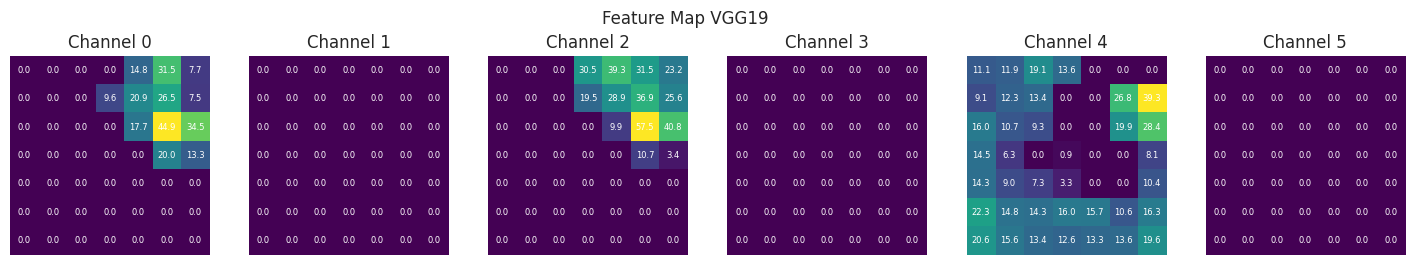

In [ ]:
fig, axs = plt.subplots(1, 6, figsize=(18, 3))

for i in range(6):
    feature_map = features_before[0, :, :, i]

    axs[i].imshow(feature_map, cmap='viridis')
    axs[i].axis('off')
    axs[i].set_title(f'Channel {i}')

    # Menampilkan nilai piksel
    h, w = feature_map.shape
    for y in range(min(h,7)):
        for x in range(min(w,7)):
            axs[i].text(x, y, f"{feature_map[y, x]:.1f}",
                        ha='center', va='center', color='white', fontsize=6)

plt.suptitle('Feature Map VGG19')
plt.show()

In [ ]:
displayed_channels = list(range(6))

mean_activation_before = {
    ch: np.mean(features_before[0, :, :, ch])
    for ch in displayed_channels
}

dominant_channel = max(
    mean_activation_before,
    key=mean_activation_before.get
)

print("Channel dominan:", dominant_channel)


Channel dominan: 4


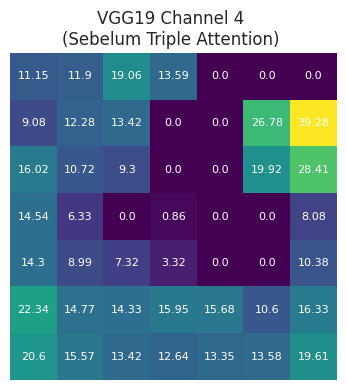

In [ ]:
channel_index = dominant_channel

channel_data = features_before[0, :, :, channel_index]

plt.figure(figsize=(4, 4))
plt.imshow(channel_data, cmap='viridis')
plt.title(f'VGG19 Channel {channel_index} \n(Sebelum Triple Attention) ')
plt.axis('off')

# Tambahkan nilai piksel
for y in range(channel_data.shape[0]):
    for x in range(channel_data.shape[1]):
        val = round(float(channel_data[y, x]), 2)
        plt.text(x, y, str(val),
                 ha='center', va='center',
                 color='white', fontsize=8)

plt.tight_layout()
plt.show()


FITUR EKSTRAKSI SETELAH TRIPLE ATTENTION

In [ ]:
x = base_model.output
x = TripleAttention()(x)

In [ ]:
x = base_model.output
x_c, x_h, x_w, fusion = TripleAttentionDebug()(x)

In [ ]:
att_debug_model = Model(inputs=base_model.input, outputs=[x_c, x_h, x_w, fusion])

In [ ]:
x_c_out, x_h_out, x_w_out, fusion_out = att_debug_model.predict(sample_image_exp)

print("Channel Attention:", x_c_out.shape)
print("Spatial Height  :", x_h_out.shape)
print("Spatial Width   :", x_w_out.shape)
print("Fusion          :", fusion_out.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Channel Attention: (1, 7, 7, 512)
Spatial Height  : (1, 7, 7, 512)
Spatial Width   : (1, 7, 7, 512)
Fusion          : (1, 7, 7, 512)


In [ ]:
def visualize_feature_with_values(feature_map, title, channel_index=0):
    """
    feature_map: shape (1, H, W, C)
    """
    data = feature_map[0, :, :, channel_index]

    plt.figure(figsize=(4, 4))
    plt.imshow(data, cmap='viridis')
    plt.title(f"{title}\nChannel {channel_index}")
    plt.axis('off')

    # Tampilkan nilai piksel
    for y in range(data.shape[0]):
        for x in range(data.shape[1]):
            val = round(float(data[y, x]), 2)
            plt.text(
                x, y, val,
                ha='center', va='center',
                color='white',
                fontsize=8
            )

    plt.tight_layout()
    plt.show()


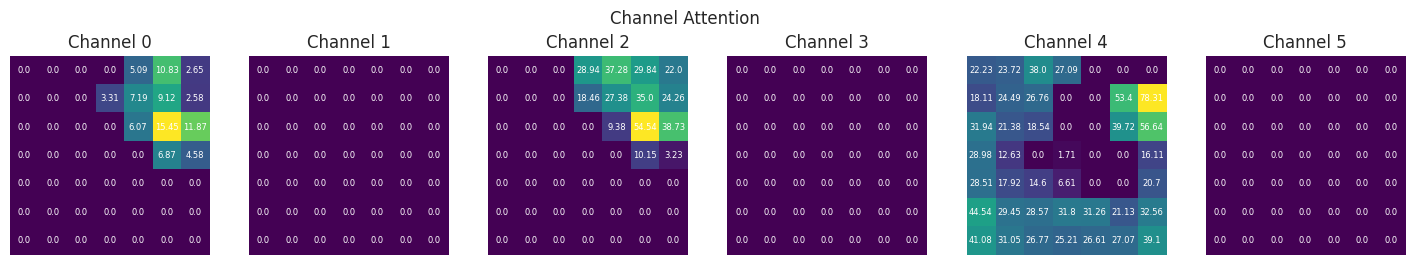

In [ ]:
fig, axs = plt.subplots(1, 6, figsize=(18,3))

for i in range(6):
    axs[i].imshow(x_c_out[0,:,:,i], cmap='viridis')
    axs[i].axis('off')
    axs[i].set_title(f'Channel {i}')

    # Tambahkan nilai piksel
    data = x_c_out[0, :, :, i]
    for y in range(data.shape[0]):
        for x in range(data.shape[1]):
            val = round(float(data[y, x]), 2)
            axs[i].text(
                x, y, str(val),
                ha='center',
                va='center',
                color='white',
                fontsize=6
            )

plt.suptitle('Channel Attention')
plt.show()

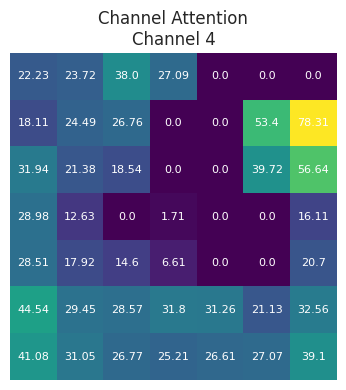

In [ ]:
visualize_feature_with_values(
    x_c_out,
    title=f"Channel Attention",
    channel_index=dominant_channel
)


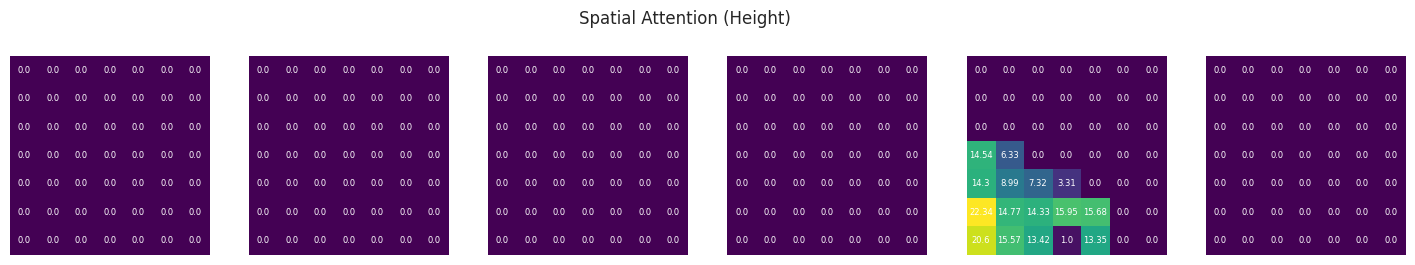

In [ ]:
fig, axs = plt.subplots(1, 6, figsize=(18,3))
for i in range(6):
    axs[i].imshow(x_h_out[0,:,:,i], cmap='viridis')
    axs[i].axis('off')

    # Tambahkan nilai piksel
    data = x_h_out[0, :, :, i]
    for y in range(data.shape[0]):
        for x in range(data.shape[1]):
            val = round(float(data[y, x]), 2)
            axs[i].text(
                x, y, str(val),
                ha='center',
                va='center',
                color='white',
                fontsize=6
            )
plt.suptitle('Spatial Attention (Height)')
plt.show()


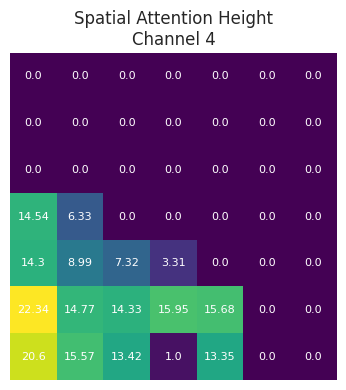

In [ ]:
visualize_feature_with_values(
    x_h_out,
    title=f"Spatial Attention Height",
    channel_index=dominant_channel
)


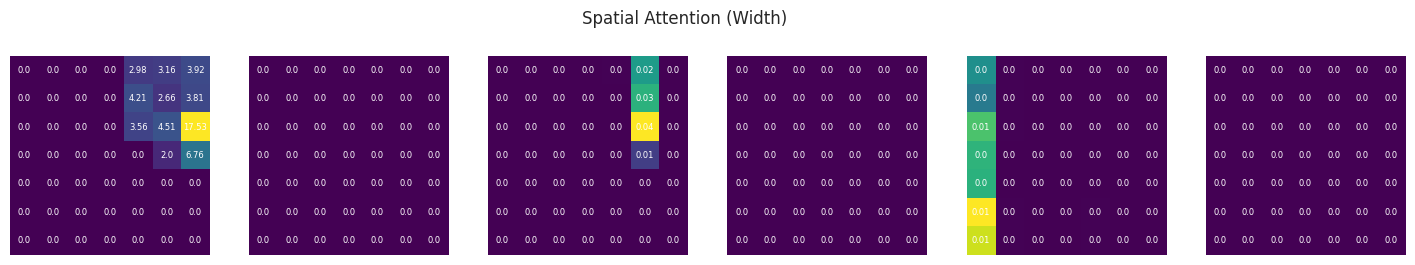

In [ ]:
fig, axs = plt.subplots(1, 6, figsize=(18,3))
for i in range(6):
    axs[i].imshow(x_w_out[0,:,:,i], cmap='viridis')
    axs[i].axis('off')

    # Tambahkan nilai piksel
    data = x_w_out[0, :, :, i]
    for y in range(data.shape[0]):
        for x in range(data.shape[1]):
            val = round(float(data[y, x]), 2)
            axs[i].text(
                x, y, str(val),
                ha='center',
                va='center',
                color='white',
                fontsize=6
            )
plt.suptitle('Spatial Attention (Width)')
plt.show()


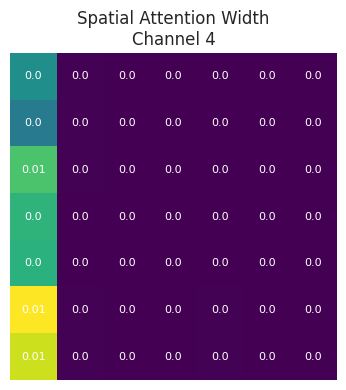

In [ ]:
visualize_feature_with_values(
    x_w_out,
    title=f"Spatial Attention Width",
    channel_index=dominant_channel
)


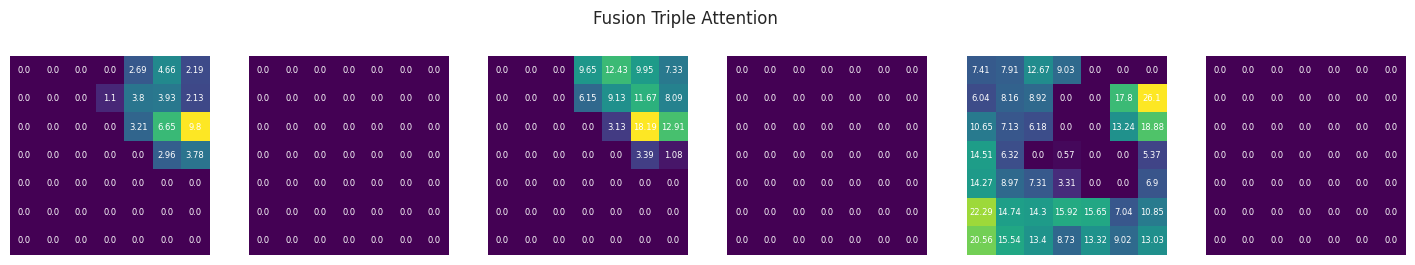

In [ ]:
fig, axs = plt.subplots(1, 6, figsize=(18,3))
for i in range(6):
    axs[i].imshow(fusion_out[0,:,:,i], cmap='viridis')
    axs[i].axis('off')

    # Tambahkan nilai piksel
    data = fusion_out[0, :, :, i]
    for y in range(data.shape[0]):
        for x in range(data.shape[1]):
            val = round(float(data[y, x]), 2)
            axs[i].text(
                x, y, str(val),
                ha='center',
                va='center',
                color='white',
                fontsize=6
            )
plt.suptitle('Fusion Triple Attention')
plt.show()

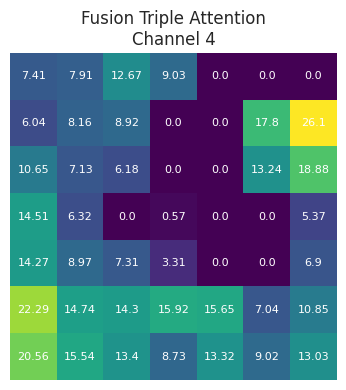

In [ ]:
visualize_feature_with_values(
    fusion_out,
    title=f"Fusion Triple Attention",
    channel_index=dominant_channel
)


**TRAINING**

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

lr = 0.0001
epochs = 30

print(f"\nTraining dengan learning rate: {lr}")

optimizer = Adam(learning_rate=lr)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Menghitung bobot kelas dari train_ds...")
y_train_labels = np.concatenate([y.numpy() for _, y in train_ds], axis=0)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_labels),
    y=y_train_labels
)
bobot_kelas = dict(enumerate(class_weights))
print(f"Bobot kelas yang diterapkan: {bobot_kelas}")

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
    class_weight=bobot_kelas
)

end_time = time.time()
training_time = end_time - start_time

def evaluate_dataset(ds, model):
    y_true = np.concatenate([y.numpy() for _, y in ds], axis=0)
    y_pred_probs = model.predict(ds, verbose=0).flatten()
    y_pred = (y_pred_probs > 0.5).astype(int)
    return y_true, y_pred, y_pred_probs

y_true_train, y_pred_train, y_prob_train = evaluate_dataset(train_ds, model)
y_true_val, y_pred_val, y_prob_val = evaluate_dataset(val_ds, model)

best_epoch = np.argmin(history.history['val_loss']) + 1

print("\nTraining selesai")
print(f"Learning rate  : {lr}")
print(f"Best epoch     : {best_epoch}")
print(f"Waktu training : {training_time:.2f} detik")


Training dengan learning rate: 0.0001
Menghitung bobot kelas dari train_ds...
Bobot kelas yang diterapkan: {0: np.float64(1.405241935483871), 1: np.float64(0.7761692650334076)}
Epoch 1/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 58s 575ms/step - accuracy: 0.8278 - loss: 0.3915 - val_accuracy: 0.8276 - val_loss: 0.4573
Epoch 2/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 250ms/step - accuracy: 0.8957 - loss: 0.2565 - val_accuracy: 0.8966 - val_loss: 0.2787
Epoch 3/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 253ms/step - accuracy: 0.9273 - loss: 0.1841 - val_accuracy: 0.8621 - val_loss: 0.4201
Epoch 4/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 260ms/step - accuracy: 0.9536 - loss: 0.1276 - val_accuracy: 0.9195 - val_loss: 0.2978
Epoch 5/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 18s 274ms/step - accuracy: 0.9837 - loss: 0.0570 - val_accuracy: 0.8851 - val_loss: 0.4656
Epoch 6/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 19s 282ms/step - accuracy: 0.9895 - loss: 0.0336 - val_accuracy: 0.8966 - val_loss: 0.4620
Epoch 7/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 18s 269ms/

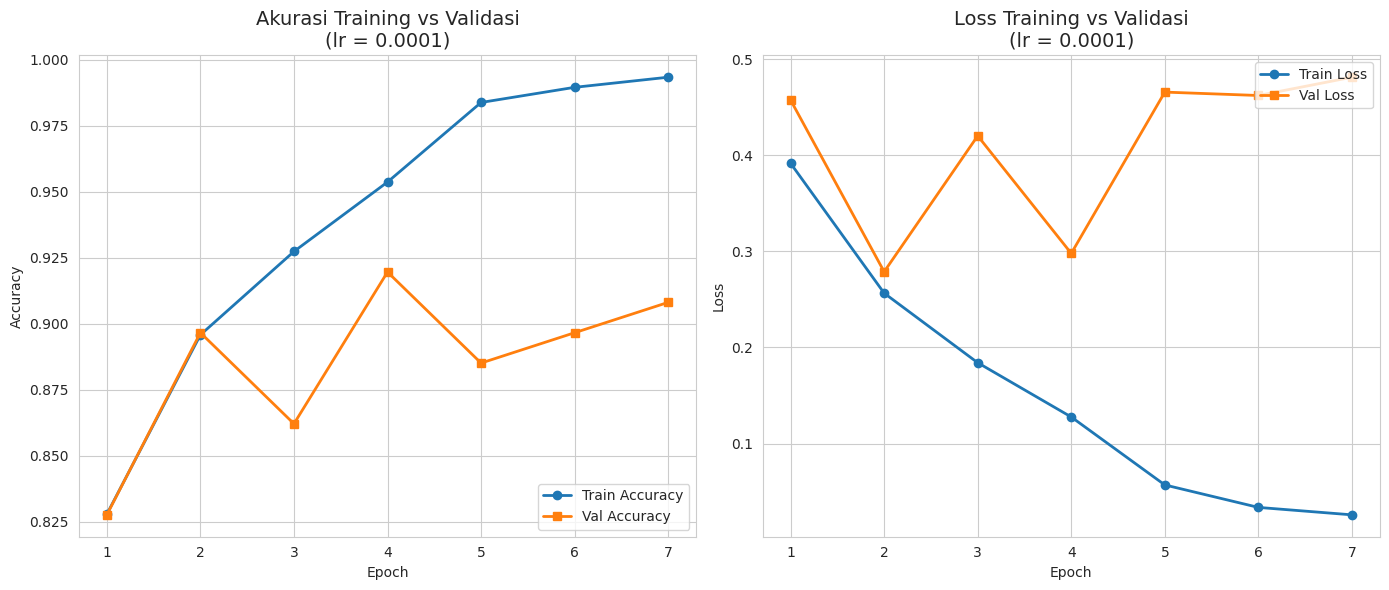

In [ ]:
def plot_history(history, lr):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs_range = range(1, len(acc) + 1)

    # Gunakan style seaborn
    sns.set_style("whitegrid")
    plt.figure(figsize=(14, 6))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, marker='o', label='Train Accuracy', linewidth=2)
    plt.plot(epochs_range, val_acc, marker='s', label='Val Accuracy', linewidth=2)
    plt.title(f'Akurasi Training vs Validasi\n(lr = {lr})', fontsize=14)
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True)

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, marker='o', label='Train Loss', linewidth=2)
    plt.plot(epochs_range, val_loss, marker='s', label='Val Loss', linewidth=2)
    plt.title(f'Loss Training vs Validasi\n(lr = {lr})', fontsize=14)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

# History plot
plot_history(history, lr)

**SIMPAN BEST MODEL**

In [ ]:
save_dir = '/content/drive/MyDrive/SKRIPSI/Skenario 1&2/best model skenario 1'
os.makedirs(save_dir, exist_ok=True)  # Buat folder jika belum ada

save_path = os.path.join(save_dir, 'best_model.h5')

# Simpan model terbaik (sudah otomatis best karena EarlyStopping restore_best_weights=True)
model.save(save_path)

print(f"Model terbaik berhasil disimpan ke: {save_path}")


Model terbaik berhasil disimpan ke: /content/drive/MyDrive/SKRIPSI/Skenario 1&2/best model skenario 1/best_model.h5


**TESTING**

LOAD DATA

In [ ]:
from tensorflow.keras.models import load_model

model_path = "/content/drive/MyDrive/SKRIPSI/Skenario 1&2/best model skenario 1/best_model.h5"

best_model_loaded = load_model(
    model_path,
    custom_objects={
        'TripleAttention': TripleAttention,
        'ChannelAttention': ChannelAttention,
        'SpatialAttention': SpatialAttention
    }
)

print(f"Model berhasil dimuat dari: {model_path}")



Model berhasil dimuat dari: /content/drive/MyDrive/SKRIPSI/Skenario 1&2/best model skenario 1/best_model.h5


In [ ]:
best_model_loaded.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ triple_attention                │ (None, 7, 7, 512)      │        65,634 │
│ (TripleAttention)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 20,355,237 (77.65 MB)

 Trainable params: 7,409,251 (28.26 MB)

 Non-trainable params: 12,945,984 (49.39 MB)

 Optimizer params: 2 (12.00 B)

In [ ]:
def run_test(model, test_ds):
    start_time = time.time()

    y_pred_probs = model.predict(test_ds).flatten()
    y_pred = (y_pred_probs > 0.5).astype(int)
    y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)

    end_time = time.time()
    print(f"Waktu inferensi: {end_time - start_time:.2f} detik")

    return y_true, y_pred, y_pred_probs

In [ ]:
y_true_test, y_pred_test, y_probs_test = run_test(best_model_loaded, test_ds)

3/3 ━━━━━━━━━━━━━━━━━━━━ 16s 7s/step
Waktu inferensi: 21.15 detik


=== Classification Report ===
              precision    recall  f1-score   support

  Lumpy Skin       0.93      0.87      0.90        31
 Normal Skin       0.93      0.96      0.95        57

    accuracy                           0.93        88
   macro avg       0.93      0.92      0.92        88
weighted avg       0.93      0.93      0.93        88

=== Confusion Matrix ===


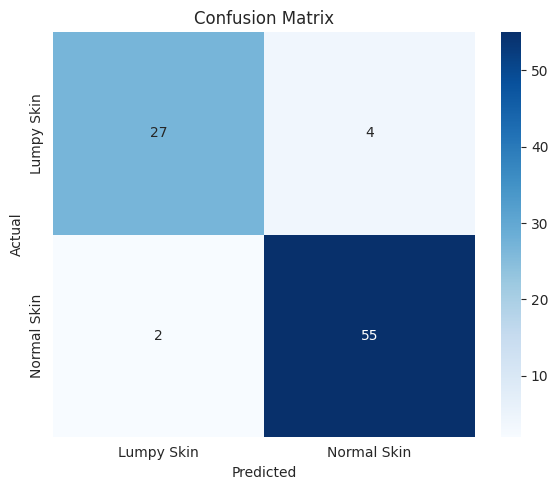

In [ ]:
def evaluate_test_results(y_true, y_pred, y_pred_probs):
    print("=== Classification Report ===")
    print(classification_report(y_true, y_pred, target_names=['Lumpy Skin', 'Normal Skin']))

    print("=== Confusion Matrix ===")
    cm = confusion_matrix(y_true, y_pred)
    labels = ['Lumpy Skin', 'Normal Skin']
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

evaluate_test_results(y_true_test, y_pred_test, y_probs_test)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

acc = accuracy_score(y_true_test, y_pred_test)
prec = precision_score(y_true_test, y_pred_test)
rec = recall_score(y_true_test, y_pred_test)
f1 = f1_score(y_true_test, y_pred_test)

print("=== Ringkasan Evaluasi Test Set ===")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-score  : {f1:.4f}")

=== Ringkasan Evaluasi Test Set ===
Accuracy  : 0.9318
Precision : 0.9322
Recall    : 0.9649
F1-score  : 0.9483


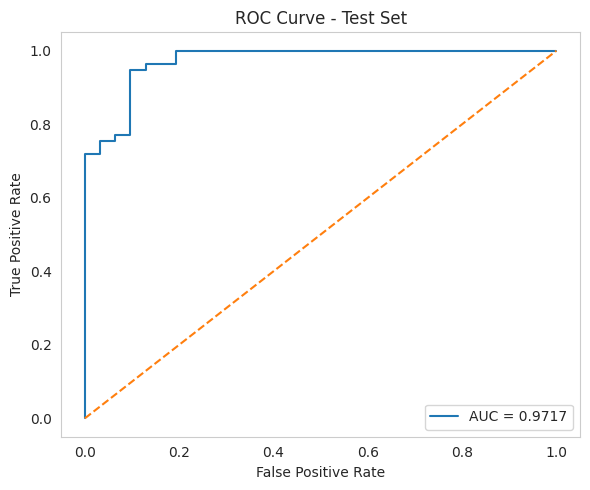

Nilai AUC: 0.9717


In [ ]:
from sklearn.metrics import roc_curve, auc

def plot_roc_curve(y_true, y_probs):
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.4f}')
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve - Test Set')
    plt.legend(loc='lower right')
    plt.grid()
    plt.tight_layout()
    plt.show()

    print(f"Nilai AUC: {roc_auc:.4f}")

plot_roc_curve(y_true_test, y_probs_test)

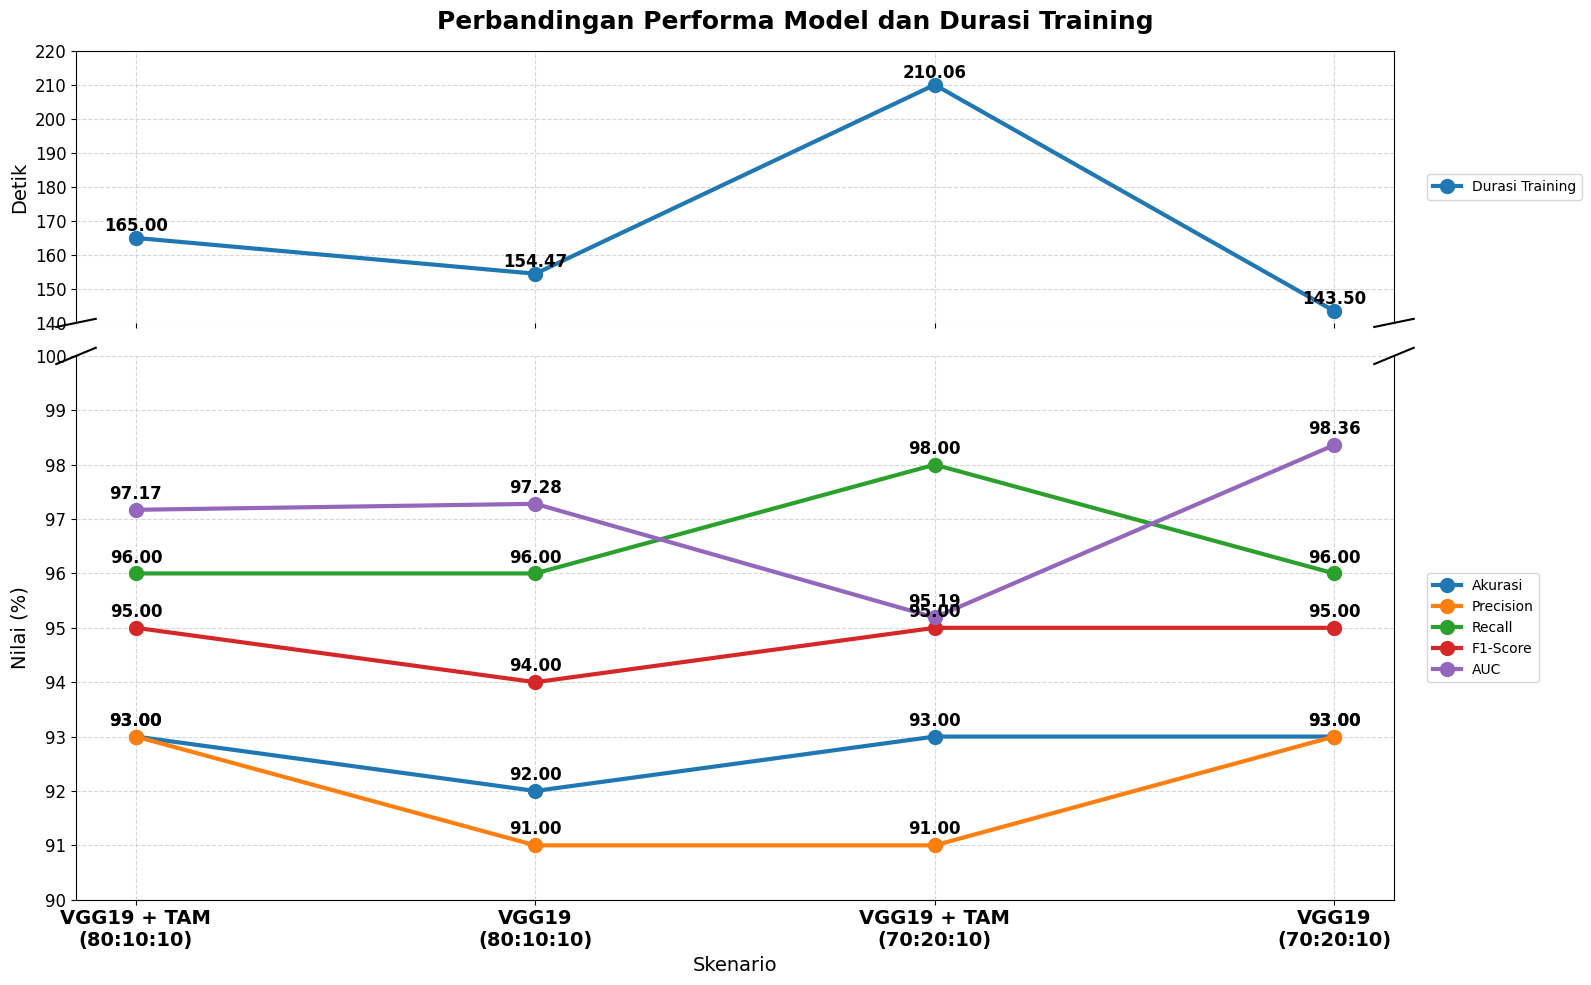

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

skenario = [
    'VGG19 + TAM\n(80:10:10)',
    'VGG19\n(80:10:10)',
    'VGG19 + TAM\n(70:20:10)',
    'VGG19\n(70:20:10)'
]

akurasi = [93, 92, 93, 93]
precision = [93, 91, 91, 93]
recall = [96, 96, 98, 96]
f1_score = [95, 94, 95, 95]
auc = [97.17, 97.28, 95.19, 98.36]
durasi = [165.00, 154.47, 210.06, 143.50]

fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1,
    figsize=(16, 10),
    sharex=True,
    gridspec_kw={'height_ratios': [1, 2]}
)

# ==========================
# BAGIAN ATAS (Durasi)
# ==========================
metrics_top = {'Durasi Training': durasi}

for nama, nilai in metrics_top.items():
    ax_top.plot(
        skenario,
        nilai,
        marker='o',
        linewidth=3,
        markersize=10,
        label=nama
    )

for i, y in enumerate(durasi):
    ax_top.text(
        i, y + 2,
        f'{y:.2f}',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

ax_top.set_ylim(140, 220)
ax_top.set_ylabel('Detik', fontsize=14)
ax_top.grid(True, linestyle='--', alpha=0.5)

ax_top.legend(
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)
)

ax_top.tick_params(axis='y', labelsize=12)

# ==========================
# BAGIAN BAWAH (Performa)
# ==========================
metrics = {
    'Akurasi': akurasi,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1_score,
    'AUC': auc
}

for nama, nilai in metrics.items():
    ax_bottom.plot(
        skenario,
        nilai,
        marker='o',
        linewidth=3,
        markersize=10,
        label=nama
    )

    for i, y in enumerate(nilai):
        ax_bottom.text(
            i, y + 0.2,
            f'{y:.2f}',
            ha='center',
            fontsize=12,
            fontweight='bold'
        )

ax_bottom.set_ylim(90, 100)
ax_bottom.set_yticks([90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100])

ax_bottom.set_ylabel('Nilai (%)', fontsize=14)
ax_bottom.set_xlabel('Skenario', fontsize=14)

ax_bottom.grid(True, linestyle='--', alpha=0.5)

ax_bottom.legend(
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)
)

# ==========================
# BESARKAN TULISAN SKENARIO
# ==========================
ax_bottom.tick_params(axis='x', labelsize=14)
ax_bottom.tick_params(axis='y', labelsize=12)
ax_top.tick_params(axis='y', labelsize=12)

plt.setp(ax_bottom.get_xticklabels(), fontsize=14, fontweight='bold')

# ==========================
# BREAK AXIS STYLE
# ==========================
ax_top.spines['bottom'].set_visible(False)
ax_bottom.spines['top'].set_visible(False)

d = .015

kwargs = dict(transform=ax_top.transAxes,
              color='k',
              clip_on=False)

ax_top.plot((-d, +d), (-d, +d), **kwargs)
ax_top.plot((1 - d, 1 + d), (-d, +d), **kwargs)

kwargs.update(transform=ax_bottom.transAxes)

ax_bottom.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_bottom.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

# ==========================
# JUDUL
# ==========================
plt.suptitle(
    'Perbandingan Performa Model dan Durasi Training',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()